## 1. Install dependencies

Run once per fresh Colab runtime.

In [11]:
!pip -q install huggingface_hub

In [12]:
import os
import zipfile
import tarfile
import shutil
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from io import BytesIO
from PIL import Image, UnidentifiedImageError
from torchvision import transforms
from torchvision.models import resnet18
from google.colab import files
from huggingface_hub import HfApi, hf_hub_download

# ------------------------------------------------------------
# 1. Device and Hugging Face repository
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Inference device:", device)

MODEL_REPO_ID = "Aayush1606/RESNET_18_FILE"
MODEL_DIR = Path("/content/resnet18_hf_model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Clear only previously extracted/downloaded files from this demo folder.
for item in MODEL_DIR.iterdir():
    if item.is_dir():
        shutil.rmtree(item)
    else:
        item.unlink()

api = HfApi()
repo_files = api.list_repo_files(repo_id=MODEL_REPO_ID, repo_type="model")
print("\nFiles found in Hugging Face repository:")
for name in repo_files:
    print(" -", name)

# ------------------------------------------------------------
# 2. Download repository files and extract archives recursively
#    Supports .zip, .tar, .tar.gz and common PyTorch checkpoint files.
# ------------------------------------------------------------
downloaded_files = []
for name in repo_files:
    if name == ".gitattributes":
        continue
    try:
        local_path = hf_hub_download(
            repo_id=MODEL_REPO_ID,
            filename=name,
            repo_type="model"
        )
        downloaded_files.append(Path(local_path))
    except Exception as e:
        print(f"Could not download {name}: {e}")

def extract_archives_recursively(source_paths, destination, max_rounds=4):
    """Extract nested archives, without extracting PyTorch-formatted .pth.zip files or files outside destination."""
    known_paths = list(source_paths)
    for _ in range(max_rounds):
        extracted_any = False
        for path in list(known_paths):
            # Do not extract zip files if they represent a direct PyTorch model package (e.g. .pth.zip or .pt.zip)
            if path.name.lower().endswith(('.pth.zip', '.pt.zip')):
                dest_path = destination / path.name
                if not dest_path.exists():
                    shutil.copy2(path, dest_path)
                if dest_path not in known_paths:
                    known_paths.append(dest_path)
                continue

            try:
                if zipfile.is_zipfile(path):
                    with zipfile.ZipFile(path) as archive:
                        archive.extractall(destination)
                    known_paths.remove(path)
                    extracted_any = True
                elif tarfile.is_tarfile(path):
                    with tarfile.open(path) as archive:
                        archive.extractall(destination)
                    known_paths.remove(path)
                    extracted_any = True
            except Exception as e:
                print(f"Warning: could not extract {path.name}: {e}")

        # Discover all files in extraction directory, including nested archives.
        discovered = [p for p in destination.rglob("*") if p.is_file()]
        for p in discovered:
            if p not in known_paths:
                known_paths.append(p)
        if not extracted_any:
            break
    return [p for p in destination.rglob("*") if p.is_file()]

all_files = extract_archives_recursively(downloaded_files, MODEL_DIR)

print("\nFiles available after extraction:")
for p in all_files:
    print(f" - {p} ({p.stat().st_size:,} bytes)")

# Checkpoint formats can have different extensions; try likely checkpoint files.
candidate_files = [
    p for p in all_files
    if p.suffix.lower() in {".pth", ".pt", ".bin", ".ckpt", ".pkl", ".pickle", ".safetensors", ".zip"}
]
# Include extensionless files, but avoid metadata and obvious image/text files.
candidate_files += [
    p for p in all_files
    if p.is_file() and not p.suffix
    and p.name not in {".gitattributes"}
    and p not in candidate_files
]

if not candidate_files:
    raise FileNotFoundError(
        "The Hugging Face repository was reached, but no model checkpoint was "
        "found after extracting its files. Check the printed file list. Upload "
        "the trained ResNet-18 .pth/.pt checkpoint (or a ZIP containing it) "
        "to this repository."
    )

# ------------------------------------------------------------
# 3. Load a state dictionary from a recognized checkpoint
# ------------------------------------------------------------
checkpoint = None
checkpoint_path = None
load_errors = []

for candidate in candidate_files:
    try:
        # weights_only=False supports older checkpoints containing metadata.
        # Use this only with a repository you trust.
        try:
            loaded = torch.load(candidate, map_location="cpu", weights_only=False)
        except TypeError:
            loaded = torch.load(candidate, map_location="cpu")

        if isinstance(loaded, nn.Module):
            # A complete serialized model is handled separately below.
            checkpoint, checkpoint_path = loaded, candidate
            break

        if isinstance(loaded, dict):
            if "model_state_dict" in loaded:
                state_dict = loaded["model_state_dict"]
            elif "state_dict" in loaded:
                state_dict = loaded["state_dict"]
            elif "model" in loaded and isinstance(loaded["model"], dict):
                state_dict = loaded["model"]
            else:
                state_dict = loaded

            # Keep tensor entries only, and remove common wrapper prefixes.
            state_dict = {
                str(k).removeprefix("module.").removeprefix("model."): v
                for k, v in state_dict.items()
                if torch.is_tensor(v)
            }

            # A ResNet state dict should include these two keys.
            if "conv1.weight" in state_dict and "fc.weight" in state_dict:
                checkpoint = {
                    "state_dict": state_dict,
                    "metadata": loaded if isinstance(loaded, dict) else {}
                }
                checkpoint_path = candidate
                break

        load_errors.append(f"{candidate.name}: file loaded but was not a recognized ResNet checkpoint")
    except Exception as e:
        load_errors.append(f"{candidate.name}: {type(e).__name__}: {e}")

if checkpoint is None:
    details = "\n".join(load_errors[-8:])
    raise RuntimeError(
        "Files were downloaded, but none could be read as a ResNet-18 checkpoint.\n"
        "Please confirm the repository contains the trained PyTorch weights.\n"
        + details
    )

print("\nUsing checkpoint:", checkpoint_path)

# ------------------------------------------------------------
# 4. Rebuild model with the same input-channel count and class count
# ------------------------------------------------------------
if isinstance(checkpoint, nn.Module):
    model = checkpoint
    # Infer class labels if possible; otherwise use the project's four labels.
    class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]
    saved_epoch = "not recorded"
    saved_macro_f1 = "not recorded"
    input_channels = model.conv1.in_channels if hasattr(model, "conv1") else 3
else:
    state_dict = checkpoint["state_dict"]
    metadata = checkpoint["metadata"]

    input_channels = int(state_dict["conv1.weight"].shape[1])
    num_classes = int(state_dict["fc.weight"].shape[0])

    default_class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]
    class_names = metadata.get("class_names", default_class_names)
    if isinstance(class_names, dict):
        # Handle maps such as {"glioma": 0, ...} or {0: "glioma", ...}.
        if all(isinstance(v, int) for v in class_names.values()):
            class_names = [k for k, v in sorted(class_names.items(), key=lambda x: x[1])]
        else:
            class_names = [v for k, v in sorted(class_names.items(), key=lambda x: int(k))]
    class_names = list(class_names)

    if len(class_names) != num_classes:
        print(
            f"Warning: checkpoint has {num_classes} output classes but metadata "
            f"contains {len(class_names)} labels. Using generic labels to avoid "
            "incorrectly naming predictions."
        )
        class_names = [f"class_{i}" for i in range(num_classes)]

    saved_epoch = metadata.get("epoch", "not recorded")
    saved_macro_f1 = metadata.get("best_val_macro_f1", "not recorded")

    model = resnet18(weights=None)
    if input_channels == 1:
        model.conv1 = nn.Conv2d(
            1, 64, kernel_size=7, stride=2, padding=3, bias=False
        )
    elif input_channels != 3:
        raise ValueError(
            f"Unsupported ResNet input channel count: {input_channels}. "
            "Expected 1 (grayscale) or 3 (RGB-trained checkpoint)."
        )
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    model.load_state_dict(state_dict, strict=True)

model = model.to(device)
model.eval()

print("Model loaded successfully.")
print("Expected input channels:", input_channels)
print("Classes:", class_names)
print("Checkpoint epoch:", saved_epoch)
print("Saved validation Macro-F1:", saved_macro_f1)
print("\nNext, run the preprocessing and MRI upload cells.")

Inference device: cpu

Files found in Hugging Face repository:
 - .gitattributes
 - resnet18_brain_tumor_best.pth.zip

Files available after extraction:
 - /content/resnet18_hf_model/resnet18_brain_tumor_best.pth.zip (44,771,595 bytes)

Using checkpoint: /content/resnet18_hf_model/resnet18_brain_tumor_best.pth.zip
Model loaded successfully.
Expected input channels: 1
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Checkpoint epoch: 10
Saved validation Macro-F1: 0.9486540036224679

Next, run the preprocessing and MRI upload cells.


In [13]:
IMAGE_SIZE = 224

# The displayed/uploaded MRI is always converted to grayscale.
# Normalize the single grayscale channel, then repeat it only if the saved
# checkpoint was trained with a 3-channel ResNet-18.
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.449], std=[0.226])
])

print("Preprocessing ready: grayscale MRI, resized to 224x224.")
print("Model input channels:", input_channels)


Preprocessing ready: grayscale MRI, resized to 224x224.
Model input channels: 1


In [14]:
def predict_with_gradcam(pil_image):
    """
    Predict a class and generate a Grad-CAM attribution map.
    The map shows model attention, not a verified tumour segmentation.
    """
    gray_image = pil_image.convert("L")
    input_tensor = transform(gray_image).unsqueeze(0)
    if input_channels == 3:
        # Preserve grayscale content while matching a 3-channel checkpoint.
        input_tensor = input_tensor.repeat(1, 3, 1, 1)
    input_tensor = input_tensor.to(device)

    captured = {}
    target_layer = model.layer4[-1]

    def forward_hook(module, inputs, output):
        output.retain_grad()
        captured["features"] = output

    handle = target_layer.register_forward_hook(forward_hook)

    try:
        model.eval()
        model.zero_grad(set_to_none=True)

        with torch.enable_grad():
            logits = model(input_tensor)
            probabilities = torch.softmax(logits[0], dim=0)
            predicted_idx = int(probabilities.argmax().item())
            logits[0, predicted_idx].backward()

        features = captured["features"][0]
        grads = captured["features"].grad[0]

        # Grad-CAM: weight each feature channel by its average gradient.
        channel_weights = grads.mean(dim=(1, 2))
        cam = (channel_weights[:, None, None] * features).sum(dim=0)
        cam = torch.relu(cam).detach().float().cpu().numpy()

        # Stable normalization; avoid division by zero for nearly constant maps.
        cam = np.nan_to_num(cam, nan=0.0, posinf=0.0, neginf=0.0)
        low, high = np.percentile(cam, [1, 99.5])
        if high > low + 1e-8:
            cam = np.clip((cam - low) / (high - low), 0, 1)
        else:
            cam = np.zeros_like(cam, dtype=np.float32)

        width, height = gray_image.size
        cam = cv2.resize(cam.astype(np.float32), (width, height),
                         interpolation=cv2.INTER_CUBIC)
        cam = np.clip(cam, 0, 1)

        return gray_image, cam, predicted_idx, probabilities.detach().cpu().numpy()

    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)


def estimate_attention_box(cam, min_area_ratio=0.003, max_area_ratio=0.60):
    """
    Estimate a rectangle from the strongest connected Grad-CAM region.
    This is an attention-region estimate, not a tumour boundary.
    Returns (x, y, w, h, threshold) or None.
    """
    cam = np.asarray(cam, dtype=np.float32)
    cam = np.nan_to_num(cam, nan=0.0, posinf=0.0, neginf=0.0)
    if cam.size == 0 or float(cam.max()) <= 1e-8:
        return None

    # Smooth small pixel-level variations, then threshold strong activations.
    smooth = cv2.GaussianBlur(cam, (0, 0), sigmaX=2.0)
    positive = smooth[smooth > 0]
    if positive.size == 0:
        return None

    threshold = max(0.45, float(np.percentile(positive, 75)))
    mask = (smooth >= threshold).astype(np.uint8)

    # Close small gaps and remove isolated speckles.
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    height, width = cam.shape
    image_area = height * width
    min_area = max(20, int(min_area_ratio * image_area))
    max_area = int(max_area_ratio * image_area)

    candidates = []
    for label in range(1, count):
        x, y, w, h, area = [int(v) for v in stats[label]]
        if min_area <= area <= max_area:
            region = labels[y:y+h, x:x+w] == label
            region_score = float(smooth[y:y+h, x:x+w][region].sum())
            candidates.append((region_score, x, y, w, h, area))

    # If the strict threshold yields no usable component, relax to the top 10%
    # of heatmap pixels and try once more.
    if not candidates:
        fallback_threshold = float(np.percentile(positive, 90))
        mask = (smooth >= fallback_threshold).astype(np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
        for label in range(1, count):
            x, y, w, h, area = [int(v) for v in stats[label]]
            if min_area <= area <= max_area:
                region = labels[y:y+h, x:x+w] == label
                region_score = float(smooth[y:y+h, x:x+w][region].sum())
                candidates.append((region_score, x, y, w, h, area))
        if not candidates:
            return None
        threshold = fallback_threshold

    # Select the connected region with the greatest total attribution.
    _, x, y, w, h, _ = max(candidates, key=lambda item: item[0])
    return x, y, w, h, threshold


Saving images (1).jpg to images (1).jpg


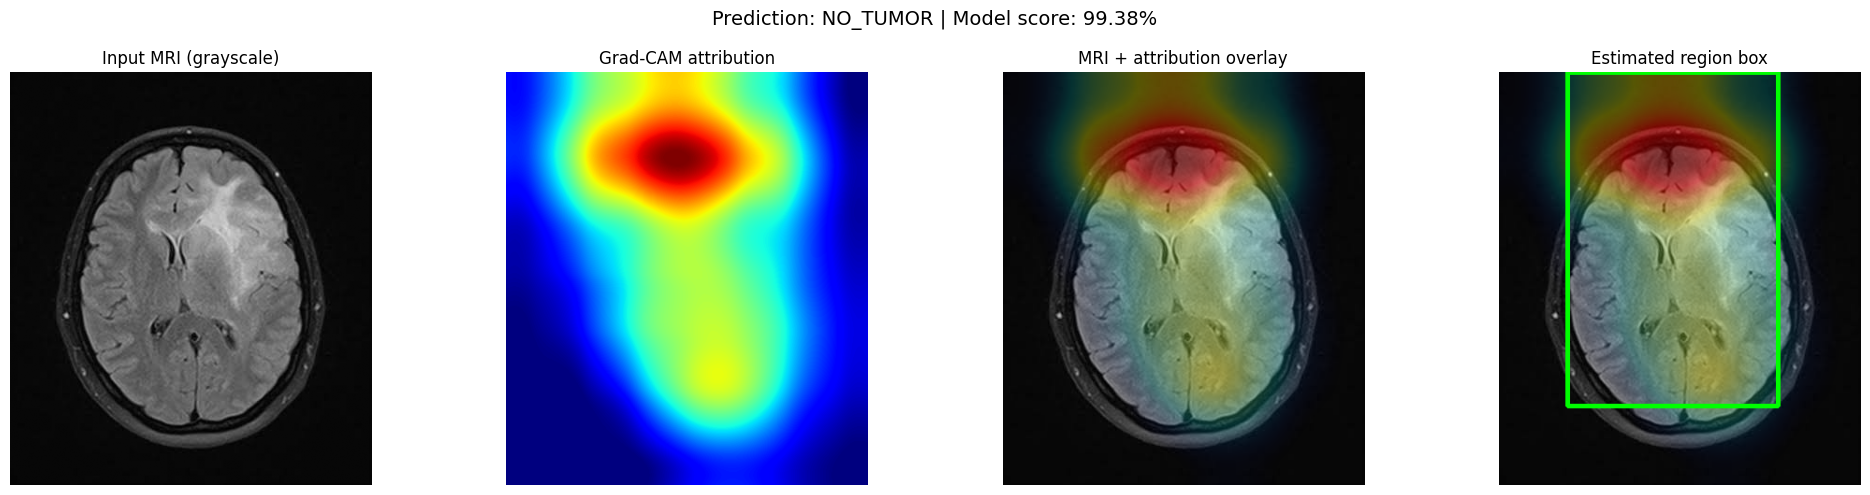

File: images (1).jpg
Predicted class: NO_TUMOR
Softmax score: 99.38%

Class-wise scores:
glioma         : 0.62%
meningioma     : 0.00%
no_tumor       : 99.38%
pituitary      : 0.00%

Estimated attention box (x, y, width, height): (73, 0, 225, 357)
Heatmap threshold used for box: 0.529
This rectangle encloses a strong connected attribution region; it is not a verified tumour boundary.

Medical-use note: Grad-CAM shows image regions influencing the model's selected prediction. It does not confirm tumour presence, location, size, or boundaries and must not be used as a clinical diagnosis.


In [15]:
uploaded_images = files.upload()

if not uploaded_images:
    print("No image uploaded.")
else:
    for filename, file_bytes in uploaded_images.items():
        try:
            with Image.open(BytesIO(file_bytes)) as img:
                original = img.copy()

            gray_image, cam, predicted_idx, probabilities = predict_with_gradcam(original)
            predicted_class = class_names[predicted_idx]
            confidence = float(probabilities[predicted_idx]) * 100

            gray_array = np.asarray(gray_image).astype(np.uint8)

            # Smooth and color the attribution map for display.
            cam_smooth = cv2.GaussianBlur(cam.astype(np.float32), (0, 0), sigmaX=1.5)
            cam_smooth = np.clip(cam_smooth, 0, 1)
            heatmap_rgb = cv2.cvtColor(
                cv2.applyColorMap(np.uint8(cam_smooth * 255), cv2.COLORMAP_JET),
                cv2.COLOR_BGR2RGB
            )

            base_rgb = np.repeat(gray_array[..., None], 3, axis=2).astype(np.float32)
            # Apply stronger color only where the attribution is meaningful.
            alpha = (0.55 * np.clip((cam_smooth - 0.10) / 0.90, 0, 1))[..., None]
            overlay = np.clip(
                base_rgb * (1 - alpha) + heatmap_rgb.astype(np.float32) * alpha,
                0, 255
            ).astype(np.uint8)

            # Estimate a box from the strongest connected attribution region.
            box = estimate_attention_box(cam_smooth)
            overlay_with_box = overlay.copy()
            if box is not None:
                x, y, w, h, box_threshold = box
                # Draw a high-contrast rectangle; keep the original overlay intact.
                cv2.rectangle(overlay_with_box, (x, y), (x + w, y + h),
                              color=(0, 255, 0), thickness=max(2, gray_array.shape[0] // 140))
                box_label = "Estimated attention region"
            else:
                box_label = "No stable region found"

            fig, axes = plt.subplots(1, 4, figsize=(20, 5))
            axes[0].imshow(gray_array, cmap="gray", vmin=0, vmax=255)
            axes[0].set_title("Input MRI (grayscale)")

            axes[1].imshow(cam_smooth, cmap="jet", vmin=0, vmax=1)
            axes[1].set_title("Grad-CAM attribution")

            axes[2].imshow(overlay)
            axes[2].set_title("MRI + attribution overlay")

            axes[3].imshow(overlay_with_box)
            axes[3].set_title("Estimated region box")

            for ax in axes:
                ax.axis("off")

            plt.suptitle(
                f"Prediction: {predicted_class.upper()} | Model score: {confidence:.2f}%",
                fontsize=14
            )
            plt.tight_layout()
            plt.show()

            print("File:", filename)
            print("Predicted class:", predicted_class.upper())
            print(f"Softmax score: {confidence:.2f}%")
            print("\nClass-wise scores:")
            for idx, name in enumerate(class_names):
                print(f"{name:15s}: {probabilities[idx] * 100:.2f}%")

            if box is not None:
                x, y, w, h, box_threshold = box
                print(f"\nEstimated attention box (x, y, width, height): ({x}, {y}, {w}, {h})")
                print(f"Heatmap threshold used for box: {box_threshold:.3f}")
                print("This rectangle encloses a strong connected attribution region; it is not a verified tumour boundary.")
            else:
                print("\nNo stable attention region could be isolated for a box on this image.")

            print(
                "\nMedical-use note: Grad-CAM shows image regions influencing the model's "
                "selected prediction. It does not confirm tumour presence, location, size, "
                "or boundaries and must not be used as a clinical diagnosis."
            )

        except (UnidentifiedImageError, OSError):
            print(f"Cannot read {filename}. Please upload a valid image file.")
        except Exception as e:
            print(f"Error processing {filename}: {e}")
